# Bacterial abundance at Pivers Island, 2011 to 2013: temperature, chlorophyll and the seasons

*OCES 3301 Assessment 2*

**Contents**: [§1 Introduction and background](#sec1) · [§2 The data](#sec2) · [§3 Correlations](#sec3) · [§4 Regression](#sec4) · [§5 PCA](#sec5) · [§6 Seasonal differences](#sec6) · [§7 Conclusion](#sec7) · [Bibliography](#bib)

-----------------

<a id="sec1"></a>

# §1 Introduction and background

The data in `PIDweekly_env_data.txt` comes from the Pivers Island Coastal Observatory (PICO), next to the Beaufort Inlet in North Carolina (34.72°N, 76.67°W), where surface water at 1 m depth was sampled weekly from January 2011 to December 2013 (Ward et al., 2017). The site is shallow (about 4.5 m) and at the mouth of an estuary, with a large seasonal cycle in temperature. There are 151 samples. After the modifications in the brief, the variables are:

* `Bacteria_abundance` $B$, the total prokaryotic cell count from flow cytometry, in cells mL⁻¹,
* `Temp` $T$, water temperature in °C,
* `Salinity` $S$, in ppt,
* `Oxygen_Saturation`, dissolved oxygen as a percentage of its saturation value, in %,
* `pH`, dimensionless,
* `DIC`, dissolved inorganic carbon, in µmol kg⁻¹,
* `Chlorophyll`, chlorophyll *a* in µg L⁻¹, a standard proxy for phytoplankton biomass,
* `NH4` (ammonium), `NO2.NO3` (nitrite plus nitrate), `PO4` (phosphate) and `SiO4` (silicate), the dissolved inorganic nutrients, in µmol L⁻¹ (ammonium probably in nmol L⁻¹, see below),
* `seasons`, the categorical label created from the sampling day.

The file does not give units, so the ones above are my best guess from the value ranges and the usual conventions. Ammonium is probably in nmol L⁻¹ rather than µmol L⁻¹, since its values are hundreds of times larger than the other nutrients. As a check that this is the dataset in the paper, the salinity has mean 32.69 and standard deviation 2.16, the same values quoted by Ward et al. (2017).

Most bacteria in the surface ocean are heterotrophs living on **dissolved organic matter** (DOM), released by phytoplankton and the rest of the food web. This route, the **microbial loop** (Azam et al., 1983, as described in Sarmiento and Gruber, 2006, p. 122), processes about half of global primary production. The bacteria are eaten by small zooplankton, compete with phytoplankton for inorganic nutrients, and both take up and release ammonium (Sarmiento and Gruber, 2006, pp. 122 and 137-138). Bacterial growth also depends on temperature. One parameterisation used in ecosystem models, from Laws et al. (2000) as quoted by Sarmiento and Gruber (2006, p. 138), gives the maximum growth rate as

$$
\mu_{\max}(T) = 1.2\,\exp\big(0.0633\,(T - 25)\big) \;\; \mathrm{d}^{-1},
$$

with $T$ in °C. This rises by a factor of $e^{0.0633 \times 25} \approx 4.9$ between 0 and 25 °C. At this site, Ward et al. (2017) found that the bacterial *community* switches between a summer and a winter composition each year, with fast transitions in spring and autumn, and argued that temperature is the most likely driver of the switch.

The aim of this notebook is to find out which of the ten environmental variables above best predict total bacterial abundance at PICO, and in particular whether temperature, which Ward et al. (2017) identified as the likely driver of the switch in community *composition*, is also the main predictor of how *many* bacteria there are.

From this, the hypotheses I test are:

1. H1 (temperature): $B$ increases with $T$. If abundance simply followed the maximum growth rate, $\ln B$ would increase linearly with $T$ with a slope of 0.0633 °C⁻¹.
2. H2 (food supply): $B$ increases with chlorophyll (more phytoplankton, so more DOM), beyond what temperature explains.
3. H3 (nutrients): there is no simple relationship between $B$ and the inorganic nutrients, since bacteria both take them up and release them.
4. H4 (seasons): $B$ differs between seasons, with winter lowest.

These are tested with correlations (§3), regression (§4), PCA (§5) and hypothesis tests (§6), with $B$ as the variable to predict.

The cell below loads the packages and sets the plotting defaults. Besides numpy, pandas and matplotlib, it uses `scipy.stats` (Virtanen et al., 2020) for the correlations and tests, and `scikit-learn` (Pedregosa et al., 2011) for the multi-linear regression and PCA, as in *04_regression.ipynb*. Both come with Colab.

In [1]:
# packages and plotting defaults
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.rcParams["font.family"] = "DejaVu Serif"
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.size"] = 12.0

The data is loaded remotely from the course repository. There are two changes from the sample code in the brief. First, `delim_whitespace=True` was removed in pandas 3.0, so the file is read with `sep=r"\s+"`, which does the same thing. Second, the season tagging uses `np.select` instead of a loop, with the same boundaries. I take `YearDay` to count days from 1 January 2011, so the samples run from 19 January 2011 to 26 December 2013, which matches the sampling period in Ward et al. (2017). This is kept as a `date` column, the dropped insolation stays in `raw` for one plot in §2b, and $\ln B$ is added for reasons given in §2c.

In [2]:
# load data remotely, tag seasons as in the brief, keep the date for time series plots
url = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/refs/heads/main/assignments/spring22/PIDweekly_env_data.txt"
raw = pd.read_csv(url, sep=r"\s+")

# winter = DecJanFeb, spring = MarAprMay, summer = JunJulAug, autumn = SepOctNov
Mar, Jun, Sep, Dec = 60, 152, 244, 335          # first day of each season (the brief's "Nov" is really 1 Dec)
day = raw["YearDay"] % 365
seasons = np.select([(day >= Mar) & (day < Jun), (day >= Jun) & (day < Sep), (day >= Sep) & (day < Dec)],
                    ["spring", "summer", "autumn"], default="winter")

df = raw.drop(columns=["YearDay", "SampleID", "Projected_Daily_Insolation", "MLLW"])
df["seasons"] = seasons
df["date"] = pd.Timestamp("2011-01-01") + pd.to_timedelta(raw["YearDay"] - 1, unit="D")
df["lnB"] = np.log(df["Bacteria_abundance"])

# fixed variable list, season order, colours and labels used in every plot
env = ["Temp", "Salinity", "Oxygen_Saturation", "pH", "DIC", "Chlorophyll", "NH4", "NO2.NO3", "PO4", "SiO4"]
short = {"lnB": r"$\ln B$", "Temp": r"$T$", "Salinity": r"$S$", "Oxygen_Saturation": r"O$_2$ sat.", "pH": "pH",
         "DIC": "DIC", "Chlorophyll": "Chl", "NH4": r"NH$_4$", "NO2.NO3": r"NO$_2$+NO$_3$", "PO4": r"PO$_4$", "SiO4": r"SiO$_4$"}
plain = {"Temp": "T", "Salinity": "S", "Oxygen_Saturation": "O2 sat.", "pH": "pH", "DIC": "DIC", "Chlorophyll": "Chl",
         "NH4": "NH4", "NO2.NO3": "NO2+NO3", "PO4": "PO4", "SiO4": "SiO4"}    # for tables
order = ["winter", "spring", "summer", "autumn"]
colours = {"winter": "tab:blue", "spring": "tab:green", "summer": "tab:red", "autumn": "tab:orange"}
label_T = r"$T$ ($^\circ$C)"
label_lnB = r"$\ln B$ ($B$ in cells mL$^{-1}$)"

--------------------
<a id="sec2"></a>

# §2 The data

## a) What is in the file

In [3]:
# zeroth order things: size, missing values, sampling interval, samples per season, ranges
gaps = df["date"].diff().dt.days
print(f"entries: {len(df)}, missing values: {df.isna().sum().sum()}, "
      f"from {df['date'].min():%d %b %Y} to {df['date'].max():%d %b %Y}")
print(f"gaps between samples: {(gaps == 7).sum()} of {gaps.count()} are 7 days, range {gaps.min():.0f} to {gaps.max():.0f} days")
print("samples per season:", df["seasons"].value_counts().loc[order].to_dict())
big = df.loc[df["NH4"].idxmax()]
print(f"largest NH4: {big['date']:%d %b %Y}, NH4 = {big['NH4']}, SiO4 = {big['SiO4']}, S = {big['Salinity']} "
      f"({(df['Salinity'] < big['Salinity']).sum()} samples are fresher)")

df[["Bacteria_abundance"] + env].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

entries: 151, missing values: 0, from 19 Jan 2011 to 26 Dec 2013
gaps between samples: 134 of 150 are 7 days, range 4 to 21 days
samples per season: {'winter': 36, 'spring': 37, 'summer': 40, 'autumn': 38}
largest NH4: 27 Sep 2011, NH4 = 3583.6, SiO4 = 36.9, S = 28.0 (3 samples are fresher)


,mean,std,min,50%,max
Bacteria_abundance,3087815.51,1083329.82,1140410.96,2973033.71,6709090.91
Temp,19.50,6.71,7.40,19.70,29.70
Salinity,32.69,2.16,26.50,33.00,38.00
Oxygen_Saturation,95.90,5.44,82.20,95.30,109.50
pH,7.94,0.05,7.83,7.93,8.08
DIC,2068.25,72.35,1853.20,2079.10,2189.13
Chlorophyll,4.92,2.21,1.53,4.59,11.84
NH4,225.40,391.82,2.00,130.50,3583.60
NO2.NO3,0.08,0.17,0.00,0.02,1.53
PO4,0.06,0.04,0.00,0.05,0.29


There are 151 samples and no missing values. Of the 150 gaps between samples, 134 are exactly 7 days and the rest are between 4 and 21 days, so this is close to an evenly spaced weekly time series, and the four seasons have similar numbers of samples (36 to 40). Bacterial abundance ranges from 1.1 to 6.7 million cells mL⁻¹, a factor of about 6, and temperature from 7.4 to 29.7 °C. The nutrients are mostly low with occasional large values: ammonium has a median of 131 but a maximum of 3584, and silicate a median of 3.5 µmol L⁻¹ but a maximum of 36.9. Both maxima are in the same sample (27 September 2011), which is also one of the freshest (salinity 28.0), so it looks like a pulse of runoff water, consistent with the post-storm nutrient pulses mentioned by Ward et al. (2017). I keep it in, since there is no reason to think it is an error.

## b) Time series and seasonal cycle

The top panel below plots $B$ and $T$ against time. The bottom panel averages $\ln B$, $T$, chlorophyll and the (dropped) insolation by calendar month over the three years, and standardises each set of 12 monthly means (subtract the mean, divide by the standard deviation), so that their timing can be compared on one axis.

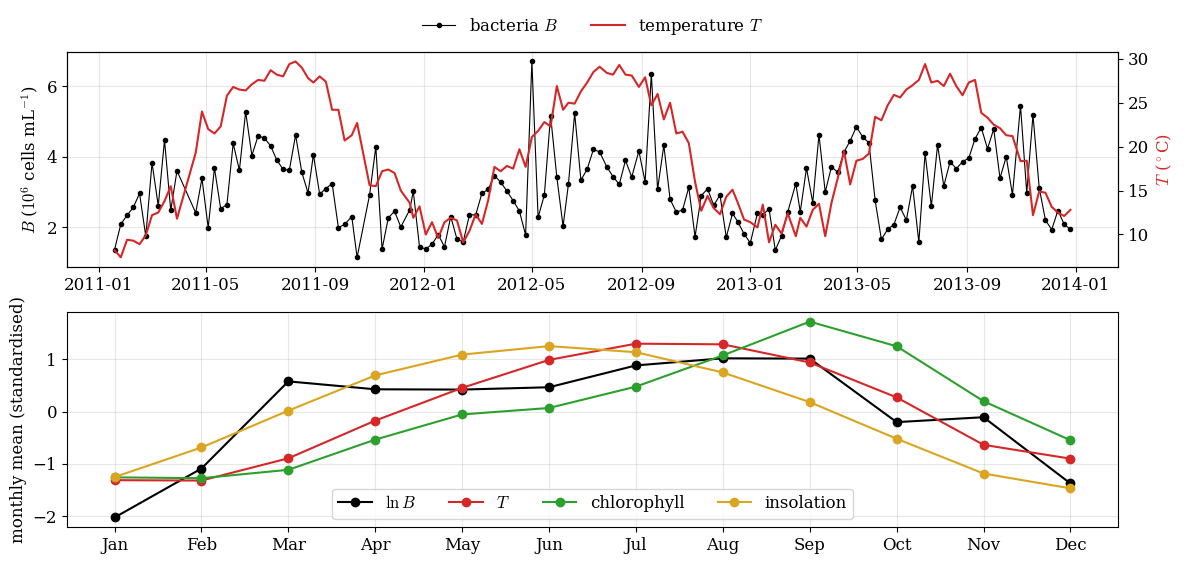

insolation: r = 0.78 with T, r = 0.50 with ln B


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
B (1e6 cells/mL),1.8,2.3,3.4,3.3,3.4,3.4,3.7,3.7,3.8,3.0,2.9,2.1
T (degC),10.5,10.4,13.3,18.1,22.4,26.0,28.0,28.0,25.6,21.1,15.0,13.2


In [4]:
# time series of B and T (top), standardised monthly means (bottom)
fig, axs = plt.subplots(2, 1, figsize=(12, 5.8))
ax = axs[0]
l1 = ax.plot(df["date"], df["Bacteria_abundance"] / 1e6, ".-", color="k", lw=0.8, label="bacteria $B$")
ax.set_ylabel(r"$B$ ($10^6$ cells mL$^{-1}$)")
ax.grid(alpha=0.3)
ax_T = ax.twinx()
l2 = ax_T.plot(df["date"], df["Temp"], color="tab:red", lw=1.5, label="temperature $T$")
ax_T.set_ylabel(label_T, color="tab:red")
ax.legend(handles=l1 + l2, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)

month = df["date"].dt.month
clim = pd.DataFrame({r"$\ln B$": df["lnB"], r"$T$": df["Temp"], "chlorophyll": df["Chlorophyll"],
                     "insolation": raw["Projected_Daily_Insolation"]}).groupby(month).mean()
clim = (clim - clim.mean()) / clim.std()
for name, c in zip(clim.columns, ["k", "tab:red", "tab:green", "goldenrod"]):
    axs[1].plot(clim.index, clim[name], "o-", color=c, label=name)
axs[1].set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axs[1].set_ylabel("monthly mean (standardised)")
axs[1].legend(ncol=4, loc="lower center")
axs[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

monthly = pd.DataFrame({"B (1e6 cells/mL)": df["Bacteria_abundance"].groupby(month).mean() / 1e6,
                        "T (degC)": df["Temp"].groupby(month).mean()}).T
monthly.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(f"insolation: r = {raw['Projected_Daily_Insolation'].corr(df['Temp']):.2f} with T, "
      f"r = {raw['Projected_Daily_Insolation'].corr(df['lnB']):.2f} with ln B")
monthly.round(1)

The top panel shows the same pattern in each of the three years. $B$ is lowest in winter, at around 1 to 2 million cells mL⁻¹, rises quickly in early spring and then stays at roughly 3 to 4 million cells mL⁻¹ until early autumn, with a lot of week-to-week scatter. In the bottom panel the four variables peak at different times: insolation in June, temperature in July and August, and chlorophyll in September. $\ln B$ has a broad maximum in August and September, at the same time as chlorophyll, but most of its rise from the winter low happens by March: its monthly mean jumps from 2.3 to 3.4 million cells mL⁻¹ between February and March, while the monthly mean temperature only goes from 10.4 to 13.3 °C, and then stays between 3.3 and 3.8 million until September. The autumn decline also happens at higher temperatures than the spring rise (2.9 million cells mL⁻¹ in November at 15.0 °C, against 3.4 million in March at 13.3 °C). This looks more like the two-state summer and winter switch that Ward et al. (2017) describe for the community composition than a smooth response to temperature.

> NOTE: Insolation was dropped in the brief because it is a close proxy for the season and temperature. It does correlate with $T$ ($r = 0.78$), but it leads temperature by one to two months (June against July and August), so it is not completely redundant. I come back to it in §7.

## c) Distribution of bacterial abundance

Pearson correlation, least-squares regression and ANOVA all work best when the data is roughly normal (for regression it is the residuals that matter, checked in §4a). The cell below compares the distribution of $B$ with that of $\ln B$ and applies the Shapiro-Wilk test (*06_statistical_tests.ipynb*), with $H_0$ that the data is normally distributed, to each.

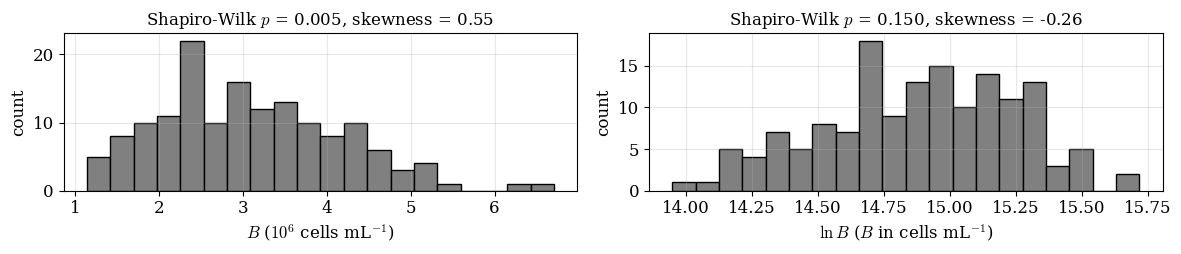

In [5]:
# histograms of B and ln B, with Shapiro-Wilk p-values and skewness
fig, axs = plt.subplots(1, 2, figsize=(12, 2.7))
for ax, x, lab in zip(axs, [df["Bacteria_abundance"] / 1e6, df["lnB"]], [r"$B$ ($10^6$ cells mL$^{-1}$)", label_lnB]):
    ax.hist(x, bins=20, color="grey", edgecolor="k")
    ax.set_title(f"Shapiro-Wilk $p$ = {stats.shapiro(x).pvalue:.3f}, skewness = {stats.skew(x):.2f}", fontsize=12)
    ax.set_xlabel(lab)
    ax.set_ylabel("count")
    ax.grid(alpha=0.3)
plt.tight_layout()

$B$ is skewed to the right (skewness 0.55) and Shapiro-Wilk rejects normality ($p = 0.005$), while $\ln B$ is close to symmetric (skewness $-0.26$) and the test fails to reject normality ($p = 0.15$). A log transform is also natural for a population, since growth and losses act multiplicatively, and it turns the exponential temperature dependence of $\mu_{\max}$ into a straight line. I therefore work with $\ln B$ from here on. A difference of 0.1 in $\ln B$ is roughly a 10% difference in $B$.

--------------------
<a id="sec3"></a>

# §3 Correlations

The matrix below shows the Pearson correlation coefficient $r$ between every pair of $\ln B$ and the ten environmental variables (lower triangle only, since it is symmetric). The table gives the Pearson and Spearman (rank) correlation of each variable with $\ln B$, with $p$-values for $H_0$ of zero correlation, and the lag-1 autocorrelation of each series (the correlation between one week and the next, see the NOTE below).

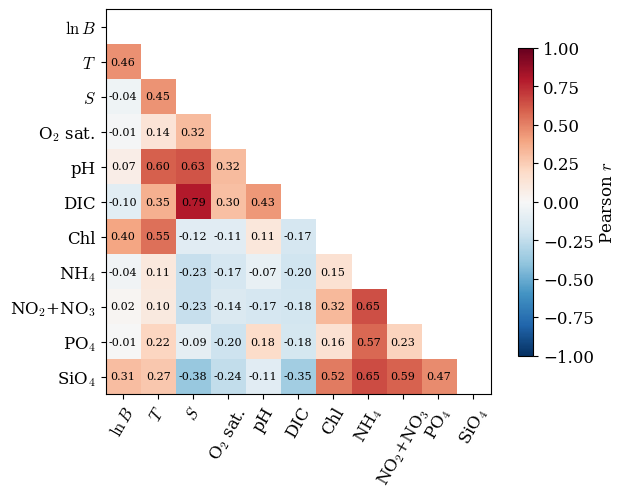

In [6]:
# Pearson correlation matrix of ln B and the ten environmental variables
cols = ["lnB"] + env
C = df[cols].corr()
C_low = C.where(np.tril(np.ones(C.shape), k=-1).astype(bool))    # lower triangle only, no diagonal
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(C_low, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(cols)):
    for j in range(i):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(cols)), [short[c] for c in cols], rotation=60)
ax.set_yticks(range(len(cols)), [short[c] for c in cols])
fig.colorbar(im, ax=ax, label="Pearson $r$", shrink=0.8);

In [7]:
# correlation of each variable with ln B, and lag-1 autocorrelation of each series
rows = {}
for v in env:
    r, p = stats.pearsonr(df[v], df["lnB"])
    rs, ps = stats.spearmanr(df[v], df["lnB"])
    rows[v] = {"Pearson r": f"{r:.2f}", "p": f"{p:.1e}", "Spearman": f"{rs:.2f}",
               "p (Spearman)": f"{ps:.1e}", "lag-1 autocorr.": f"{df[v].autocorr(1):.2f}"}
print(f"lag-1 autocorrelation of ln B: {df['lnB'].autocorr(1):.2f}")
pd.DataFrame(rows).T

lag-1 autocorrelation of ln B: 0.42


,Pearson r,p,Spearman,p (Spearman),lag-1 autocorr.
Temp,0.46,2.7e-09,0.49,1.9e-10,0.95
Salinity,-0.04,5.9e-01,-0.01,8.7e-01,0.50
Oxygen_Saturation,-0.01,9.0e-01,-0.04,6.3e-01,0.50
pH,0.07,4.1e-01,0.05,5.1e-01,0.63
DIC,-0.10,2.1e-01,-0.05,5.3e-01,0.62
Chlorophyll,0.40,5.0e-07,0.45,7.5e-09,0.58
NH4,-0.04,6.5e-01,-0.09,2.5e-01,0.20
NO2.NO3,0.02,8.4e-01,-0.18,2.4e-02,0.21
PO4,-0.01,9.3e-01,0.05,5.1e-01,0.42
SiO4,0.31,1.2e-04,0.48,4.0e-10,0.34


Only three variables have a correlation with $\ln B$ larger than 0.15 in size: temperature ($r = 0.46$), chlorophyll ($r = 0.40$) and silicate ($r = 0.31$), all positive. For the other seven, $|r| \leq 0.10$ and $p > 0.2$, so I fail to reject zero correlation. That is no evidence of a *linear* relationship, and says nothing about non-linear ones. Spearman gives a similar picture, except that silicate's rank correlation (0.48) is much higher than its Pearson value. Silicate has a long right tail (§2a), which affects the linear correlation more than the ranks. With 20 tests (ten variables, Pearson and Spearman) at $\alpha = 0.05$, about one false positive would be expected by chance (banana skin 4 in lecture 05). A Bonferroni correction ($\alpha/20 = 0.0025$) still keeps temperature, chlorophyll and silicate, but drops the Spearman correlation with nitrite plus nitrate ($-0.18$, $p = 0.024$).

The matrix also shows that the predictors are correlated with each other, which is exactly the problem Ward et al. (2017) point out for observational data. Temperature and chlorophyll have $r = 0.55$, so the warm months are also the months with the most phytoplankton. The nutrients form their own cluster (ammonium with silicate and with nitrite plus nitrate, both 0.65). To separate temperature from chlorophyll, the cell below computes **partial correlations**, i.e. the correlation between the parts of $\ln B$ and of one variable that are not linearly explained by a third.

In [8]:
# partial correlations: correlate the residuals after a linear fit against the control variable
def resid(y, x):
    a, b = np.polyfit(x, y, 1)
    return y - (a * x + b)

for v, ctrl in [("Chlorophyll", "Temp"), ("Temp", "Chlorophyll"), ("SiO4", "Temp")]:
    r, p = stats.pearsonr(resid(df["lnB"], df[ctrl]), resid(df[v], df[ctrl]))
    print(f"r(ln B, {v} | {ctrl}) = {r:.2f}, p = {p:.1e}")

# effective sample size for two autocorrelated series (Bretherton et al., 1999)
rB = df["lnB"].autocorr(1)
N_eff = {}
for v in ["Temp", "Chlorophyll", "SiO4"]:
    rv = df[v].autocorr(1)
    N_eff[v] = len(df) * (1 - rB * rv) / (1 + rB * rv)
    r = df["lnB"].corr(df[v])
    t = r * np.sqrt((N_eff[v] - 2) / (1 - r**2))
    print(f"{v}: N_eff = {N_eff[v]:.0f}, p = {2 * stats.t.sf(abs(t), N_eff[v] - 2):.1e}")

r(ln B, Chlorophyll | Temp) = 0.19, p = 1.9e-02
r(ln B, Temp | Chlorophyll) = 0.32, p = 7.5e-05
r(ln B, SiO4 | Temp) = 0.22, p = 7.8e-03
Temp: N_eff = 64, p = 1.2e-04
Chlorophyll: N_eff = 91, p = 1.0e-04
SiO4: N_eff = 113, p = 9.0e-04


After removing temperature, the correlation with chlorophyll drops from 0.40 to 0.19 ($p = 0.02$), while after removing chlorophyll the correlation with temperature only drops from 0.46 to 0.32 ($p = 8 \times 10^{-5}$). So the data favours temperature as the stronger predictor, with chlorophyll (H2) adding a small amount on top. Silicate keeps a partial correlation of 0.22 ($p = 0.008$) after removing temperature. I do not have a clear explanation for this; silicate tracks both runoff and diatoms, and either could be linked to the DOM supply.

> NOTE: The $p$-values above assume 151 independent samples, but neighbouring weeks are similar: the lag-1 autocorrelation is 0.95 for temperature and 0.42 for $\ln B$. Following Bretherton et al. (1999), the effective sample size for the correlation of two such series is $N_{\mathrm{eff}} \approx N (1 - r_x r_y)/(1 + r_x r_y)$, where $r_x$ and $r_y$ are the two lag-1 autocorrelations. This gives $N_{\mathrm{eff}} \approx 64$ for temperature, which raises its $p$-value from $3 \times 10^{-9}$ to about $10^{-4}$. The conclusions do not change here, but every $p$-value in this notebook is likely too small for the same reason.

--------------------
<a id="sec4"></a>

# §4 Regression

## a) $\ln B$ against temperature

Taking logs of the growth law in §1, if $B$ were proportional to $\mu_{\max}(T)$ then

$$
\ln B = a + bT,
$$

with $b = 0.0633$ °C⁻¹, where $a$ is an intercept with no particular meaning. Equivalently, the [$Q_{10}$](https://en.wikipedia.org/wiki/Q10_%28temperature_coefficient%29) $= e^{10b}$, the factor by which $B$ changes for 10 °C of warming, would be 1.88. I fit $a$ and $b$ with `stats.linregress` (as in *03_regression.ipynb*) and test $H_0$: $b = 0.0633$ °C⁻¹ at $\alpha = 0.05$ with the $t$-statistic $(\hat{b} - 0.0633)/\mathrm{SE}(\hat{b})$, on $N - 2$ degrees of freedom.

b = 0.0249 +/- 0.0039 per degC, R^2 = 0.21, p (H0: b = 0) = 2.7e-09
Q10 = 1.28 (data), 1.88 (Laws et al.)
H0: b = 0.0633: t = -9.8, p = 1.0e-17; with N_eff from section 3: t = -6.4
fitted B at 7.4 and 29.7 degC: 2.1 and 3.7 million cells/mL
residuals: Shapiro-Wilk p = 0.84
mean residual by season: {'winter': -0.16, 'spring': 0.15, 'summer': -0.01, 'autumn': 0.02}


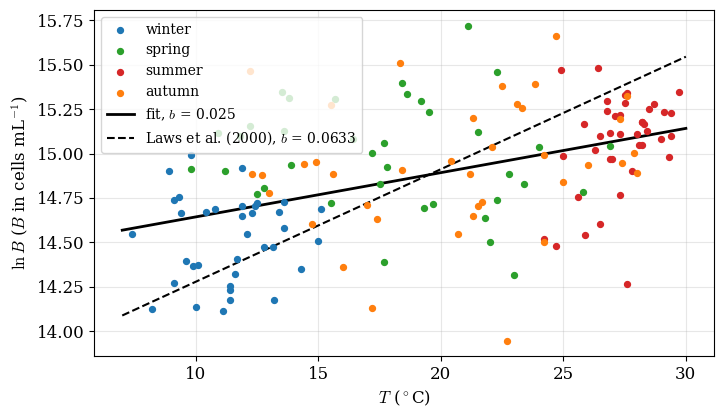

In [9]:
# ln B = a + b T, and a test of H0: b = 0.0633 per degC (Laws et al., 2000)
fit = stats.linregress(df["Temp"], df["lnB"])
b_laws = 0.0633
t = (fit.slope - b_laws) / fit.stderr
print(f"b = {fit.slope:.4f} +/- {fit.stderr:.4f} per degC, R^2 = {fit.rvalue**2:.2f}, p (H0: b = 0) = {fit.pvalue:.1e}")
print(f"Q10 = {np.exp(10 * fit.slope):.2f} (data), {np.exp(10 * b_laws):.2f} (Laws et al.)")
print(f"H0: b = {b_laws}: t = {t:.1f}, p = {2 * stats.t.sf(abs(t), len(df) - 2):.1e}; "
      f"with N_eff from section 3: t = {t * np.sqrt(N_eff['Temp'] / len(df)):.1f}")
print(f"fitted B at 7.4 and 29.7 degC: {np.exp(fit.intercept + fit.slope * 7.4) / 1e6:.1f} and "
      f"{np.exp(fit.intercept + fit.slope * 29.7) / 1e6:.1f} million cells/mL")
df["resid"] = df["lnB"] - (fit.intercept + fit.slope * df["Temp"])
print(f"residuals: Shapiro-Wilk p = {stats.shapiro(df['resid']).pvalue:.2f}")
print("mean residual by season:", df.groupby("seasons")["resid"].mean().loc[order].round(2).to_dict())

fig, ax = plt.subplots(figsize=(8, 4.5))
for s in order:
    sub = df[df["seasons"] == s]
    ax.scatter(sub["Temp"], sub["lnB"], s=18, color=colours[s], label=s, zorder=3)
T_line = np.linspace(7, 30, 50)
ax.plot(T_line, fit.intercept + fit.slope * T_line, "k-", lw=2, label=f"fit, $b$ = {fit.slope:.3f}")
ax.plot(T_line, df["lnB"].mean() + b_laws * (T_line - df["Temp"].mean()), "k--", lw=1.5,
        label=f"Laws et al. (2000), $b$ = {b_laws}")
ax.set_xlabel(label_T)
ax.set_ylabel(label_lnB)
ax.legend(fontsize=10, loc="upper left")
ax.grid(alpha=0.3, zorder=0);

So far so simple: warmer water, faster growth, more bacteria. The fitted line does go up with temperature ($\hat{b} = 0.025 \pm 0.004$ °C⁻¹, $p = 3 \times 10^{-9}$ for $H_0$: $b = 0$), but it only explains 21% of the variance in $\ln B$, and its slope is less than half of the Laws et al. (2000) value (dashed line, drawn through the mean of the data). The test rejects $H_0$: $b = 0.0633$ °C⁻¹ ($t = -9.8$, $p \approx 10^{-17}$), and still would with the smaller effective sample size from §3 ($t = -6.4$). The implied $Q_{10}$ is 1.28 rather than 1.88, so across the whole range from 7.4 to 29.7 °C the fitted $B$ only goes from 2.1 to 3.7 million cells mL⁻¹. Shapiro-Wilk fails to reject normality of the residuals ($p = 0.84$), which the $t$-tests assume.

This is not really a contradiction, because $\mu_{\max}$ is a maximum *growth rate* while $B$ is a *standing stock*. The number of cells is a balance between growth and losses, such as grazing by small zooplankton (Sarmiento and Gruber, 2006, p. 122), and if the losses also speed up in warm water, the stock can respond to temperature much less than the growth rate does. The bacteria may also be limited by the DOM supply rather than growing at $\mu_{\max}$. The seasonal residuals point to something else as well. At the same temperature, spring samples have about 16% more bacteria than the fit predicts (mean residual $+0.15$) and winter samples about 15% fewer ($-0.16$), with summer and autumn close to zero. This is the jump in early spring from §2b, which a straight line in $T$ cannot represent.

## b) Multi-linear regression and model selection

To see whether other variables add anything to temperature, I fit multi-linear models for $\ln B$ with `LinearRegression` (as in *04_regression.ipynb*), from temperature alone up to all ten variables, and compare them with the Akaike and Bayesian information criteria,

$$
\mathrm{AIC} = 2k + N\ln\sigma^2, \qquad \mathrm{BIC} = k\ln N + N\ln\sigma^2,
$$

where $k$ is the number of fitted coefficients (including the intercept), $N = 151$ is the number of samples, and $\sigma^2$ is the mean squared residual. Lower is better, and BIC penalises complexity more than AIC. The full model is also refitted on standardised inputs (mean 0, standard deviation 1), so that its coefficients, in units of $\ln B$ per standard deviation of the input, can be compared with each other.

Those models are picked from the hypotheses, so the cell also runs a greedy **forward selection** (adding at each step the variable that lowers AIC the most) and adds the four-variable model it picks to the table. Each model is also tested out of sample: it is fitted on two of the three years and used to predict the third. The **skill** column is $1 - \mathrm{MSE}/\mathrm{MSE}_0$, where MSE is the mean squared error of these predictions and $\mathrm{MSE}_0$ that of predicting the training mean, so 0 is no better than the mean and a negative value is worse.

In [10]:
# multi-linear regression for ln B, compared by AIC, BIC and out-of-sample skill
def info_criteria(inputs):
    X, y = df[inputs].values, df["lnB"].values
    model = LinearRegression().fit(X, y)
    N, k = len(y), len(inputs) + 1                 # k includes the intercept
    var = np.mean((y - model.predict(X))**2)       # sigma^2 = (l2 mismatch) / N
    return {"k": k, "R^2": model.score(X, y), "AIC": 2 * k + N * np.log(var), "BIC": k * np.log(N) + N * np.log(var)}

year = df["date"].dt.year
def skill(inputs):                                 # fit on two years, predict the third
    err, err0 = [], []
    for y in year.unique():
        tr, te = df[year != y], df[year == y]
        err.append((te["lnB"] - LinearRegression().fit(tr[inputs], tr["lnB"]).predict(te[inputs]))**2)
        err0.append((te["lnB"] - tr["lnB"].mean())**2)   # baseline: predict the training mean
    return 1 - np.concatenate(err).mean() / np.concatenate(err0).mean()

# greedy forward selection: at each step add the variable that lowers AIC the most
chosen, left = [], env.copy()
while left:
    best = min(left, key=lambda v: info_criteria(chosen + [v])["AIC"])
    chosen.append(best)
    left.remove(best)
print("forward selection order:", ", ".join(plain[v] for v in chosen))

models = {"T": ["Temp"], "Chl": ["Chlorophyll"], "T, Chl": ["Temp", "Chlorophyll"],
          "T, Chl, SiO4": ["Temp", "Chlorophyll", "SiO4"], "T, Chl, SiO4, S": ["Temp", "Chlorophyll", "SiO4", "Salinity"],
          ", ".join(plain[v] for v in chosen[:4]) + " (forward)": chosen[:4], "all ten": env}
table = pd.DataFrame({name: {**info_criteria(inputs), "skill": skill(inputs)} for name, inputs in models.items()}).T
table["k"] = table["k"].astype(int)

# standardised coefficients of the full model
full = LinearRegression().fit(StandardScaler().fit_transform(df[env]), df["lnB"])
coef = pd.DataFrame([full.coef_], index=["standardised coef."], columns=[plain[v] for v in env])
display(table.round(3), coef.round(3))

forward selection order: T, S, NH4, SiO4, pH, DIC, PO4, NO2+NO3, Chl, O2 sat.


,k,R^2,AIC,BIC,skill
T,2,0.212,-339.175,-333.140,0.162
Chl,2,0.156,-328.868,-322.833,0.126
"T, Chl",3,0.241,-342.799,-333.747,0.158
"T, Chl, SiO4",4,0.257,-344.072,-332.003,-0.102
"T, Chl, SiO4, S",5,0.294,-349.848,-334.761,-0.104
"T, S, NH4, SiO4 (forward)",5,0.360,-364.544,-349.458,0.048
all ten,11,0.411,-365.132,-331.942,0.009


,T,S,O2 sat.,pH,DIC,Chl,NH4,NO2+NO3,PO4,SiO4
standardised coef.,0.25,-0.013,0.007,-0.068,-0.082,-0.03,-0.074,-0.051,-0.06,0.127


Adding variables always raises $R^2$, from 0.21 with temperature alone to 0.41 with all ten. Among the hand-picked models, AIC prefers the full model ($-365.1$) while BIC hardly changes ($-333.1$ for temperature alone, $-331.9$ for all ten), and chlorophyll alone is worse than temperature alone by both, consistent with §3. Forward selection picks temperature first, then salinity, ammonium and silicate, with chlorophyll only ninth, and that four-variable model has a BIC of $-349.5$, well below any hand-picked model, even though salinity on its own has almost no correlation with $\ln B$ ($r = -0.04$). The out-of-sample skill does not back these extra variables, though. Temperature alone predicts a held-out year with a skill of 0.16 and adding chlorophyll leaves it unchanged, while the four-variable model only reaches 0.05 and the models with silicate and chlorophyll drop to $-0.10$, worse than predicting the mean. So the gains in AIC and BIC seem to come from fitting features of these particular three years, and the safest reading is still that temperature does most of the work.

In the full model, temperature has by far the largest standardised coefficient (0.25), followed by silicate (0.13), while chlorophyll's coefficient is close to zero and even negative ($-0.03$), although chlorophyll alone correlates with $\ln B$ at 0.40. This is what correlated inputs do to multi-linear regression: chlorophyll shares most of its information with temperature and silicate, so the fit can trade one coefficient against the others, and an individual coefficient should not be read as the effect of that variable on its own. Even the full model leaves about 60% of the variance in $\ln B$ unexplained.

--------------------
<a id="sec5"></a>

# §5 PCA

PCA (*04_regression.ipynb*) finds the uncorrelated combinations of variables that explain the most variance. I apply it to the ten environmental variables only, leaving $\ln B$ out, to first see how the environment itself is organised and then ask how the bacteria relate to it. The variables are standardised first, otherwise DIC (values around 2000) would dominate PO₄ (around 0.06) purely because of its units. The panels show the variance explained by each component, the samples in the plane of the first two components coloured by season, and the loading of each variable on those two components.

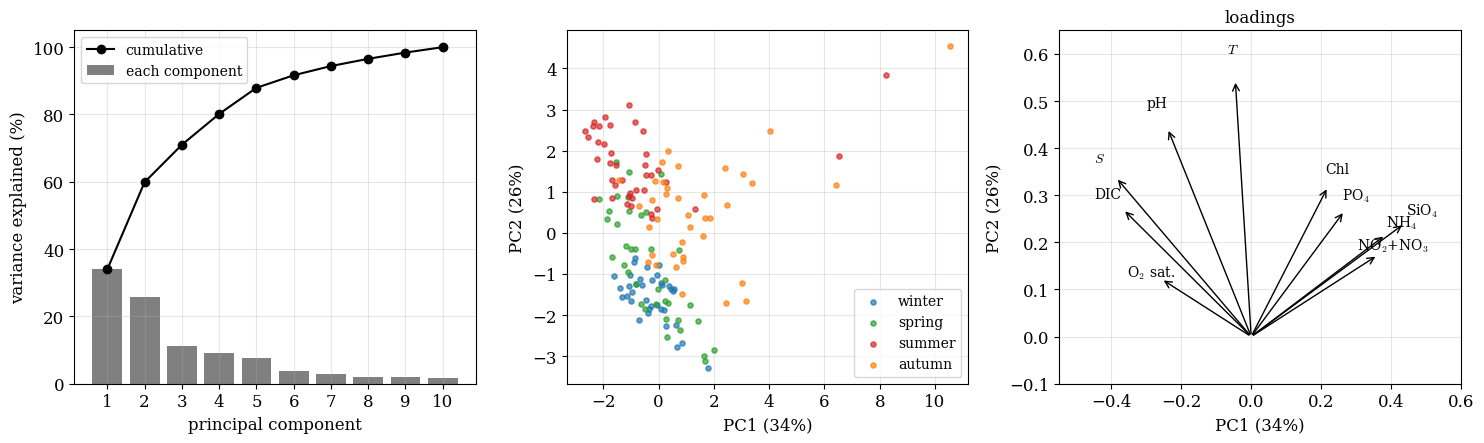

PC1: r with ln B = 0.13, p = 1.2e-01
PC2: r with ln B = 0.27, p = 9.3e-04
PC3: r with ln B = 0.43, p = 2.7e-08


,T,S,O2 sat.,pH,DIC,Chl,NH4,NO2+NO3,PO4,SiO4,winter,spring,summer,autumn
PC1,-0.05,-0.39,-0.26,-0.24,-0.37,0.22,0.38,0.36,0.27,0.44,-0.27,-0.34,-0.77,1.40
PC2,0.54,0.34,0.12,0.44,0.27,0.32,0.22,0.17,0.27,0.24,-1.55,-0.78,1.66,0.48
PC3,0.29,-0.18,-0.06,-0.05,-0.22,0.66,-0.46,-0.14,-0.41,0.06,-0.52,-0.12,0.25,0.35


In [11]:
# PCA of the ten standardised environmental variables (bacteria not included)
X = StandardScaler().fit_transform(df[env])
pca = PCA().fit(X)
pcs = pca.transform(X)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
n = np.arange(1, len(env) + 1)
axs[0].bar(n, pca.explained_variance_ratio_ * 100, color="grey", label="each component")
axs[0].plot(n, np.cumsum(pca.explained_variance_ratio_) * 100, "ko-", label="cumulative")
axs[0].set_xticks(n)
axs[0].set_xlabel("principal component")
axs[0].set_ylabel("variance explained (%)")
axs[0].legend(fontsize=10)

for s in order:
    sel = (df["seasons"] == s).values
    axs[1].scatter(pcs[sel, 0], pcs[sel, 1], s=14, color=colours[s], alpha=0.7, label=s, zorder=2)
axs[1].legend(fontsize=10)

for j, v in enumerate(env):   # loading of each variable on PC1 and PC2
    x, y = pca.components_[0, j], pca.components_[1, j]
    axs[2].annotate("", (x, y), (0, 0), arrowprops=dict(color="k", arrowstyle="->", lw=1))
    axs[2].text(1.12 * x, 1.12 * y, short[v], fontsize=10, ha="center", va="center")
axs[2].set_xlim([-0.55, 0.6])
axs[2].set_ylim([-0.1, 0.65])
axs[2].set_title("loadings", fontsize=12)
for ax in axs[1:]:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}%)")
for ax in axs:
    ax.grid(alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

# loadings, season means of each component, and correlation of each component with ln B
names = ["PC1", "PC2", "PC3"]
load = pd.DataFrame(pca.components_[:3].T, index=[plain[v] for v in env], columns=names)
season_mean = pd.DataFrame(pcs[:, :3], columns=names).groupby(df["seasons"].values).mean().loc[order]
for k, name in enumerate(names):
    r, p = stats.pearsonr(pcs[:, k], df["lnB"])
    print(f"{name}: r with ln B = {r:.2f}, p = {p:.1e}")
display(pd.concat([load, season_mean]).round(2).T)

The first three components explain 34%, 26% and 11% of the variance (71% together), after which the explained variance levels off. Reading the loadings, PC1 combines high silicate, ammonium and nitrite plus nitrate with low salinity and DIC. I would interpret this as a **runoff** axis, fresher water from the estuary carrying nutrients, and it is highest on average in autumn (+1.40). PC2 combines high temperature, pH and salinity, and is a seasonal axis, with summer at +1.66 and winter at $-1.55$ on average; it is the direction that separates the seasons in the middle panel. PC3 is dominated by chlorophyll (loading 0.66) together with low ammonium and phosphate, which looks like a phytoplankton growth axis, where phytoplankton have built up and drawn down the nutrients.

The correlation of each component with $\ln B$ is 0.13 for PC1 ($p = 0.12$), 0.27 for PC2 ($p = 9 \times 10^{-4}$) and 0.43 for PC3 ($p = 3 \times 10^{-8}$). So the bacteria are least related to the direction in which the environment varies most, and most related to the chlorophyll-dominated third component, with a correlation about as high as that of temperature itself. This is a small banana skin of PCA: the components are ranked by the *environmental* variance they explain, not by their relevance to the variable we want to predict. The PC3 result gives H2 a bit more support than the partial correlations in §3 did, although PC3 also contains some temperature (loading 0.29), so the two effects are still not fully separated.

--------------------
<a id="sec6"></a>

# §6 Seasonal differences

This section tests H4. With four seasons, I use a one-way ANOVA rather than six separate $t$-tests, which would inflate the chance of a false positive (lecture 06). The null hypothesis is $H_0$: the mean of $\ln B$ is the same in all four seasons, tested at $\alpha = 0.05$. ANOVA assumes each group is normal with equal variances, so these are checked first with Shapiro-Wilk and Levene, and I also run the Kruskal-Wallis test, a rank-based version that does not assume normality. If $H_0$ is rejected, Tukey's honest significance test (`stats.tukey_hsd`) says which pairs of seasons differ. The seasons are the calendar ones from the brief.

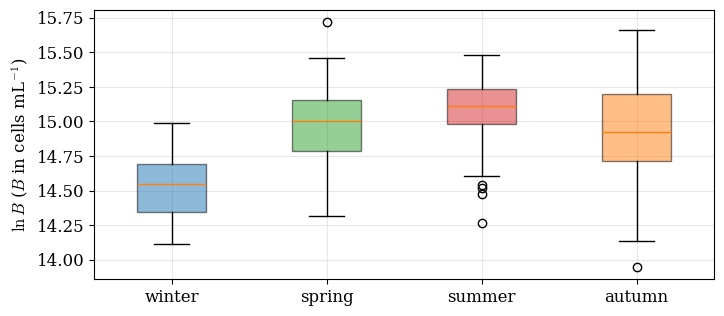

Shapiro-Wilk p: {'winter': 0.148, 'spring': 0.979, 'summer': 0.002, 'autumn': 0.491}
Levene p: 0.28 (ln B), 0.01 (B)
ANOVA: F = 24.2, p = 9.0e-13;  Kruskal-Wallis: H = 51.8, p = 3.2e-11
geometric mean B (million cells/mL): {'winter': 2.02, 'spring': 3.23, 'summer': 3.48, 'autumn': 3.03}
Tukey HSD p-values:


,winter,spring,summer,autumn
winter,1.0e+00,2.9e-09,4.0e-12,2.1e-07
spring,2.9e-09,1.0e+00,7.0e-01,8.0e-01
summer,4.0e-12,7.0e-01,1.0e+00,1.9e-01
autumn,2.1e-07,8.0e-01,1.9e-01,1.0e+00


In [12]:
# ln B by season: box plot, assumption checks, ANOVA, Kruskal-Wallis, Tukey HSD
groups = [df.loc[df["seasons"] == s, "lnB"] for s in order]
fig, ax = plt.subplots(figsize=(8, 3.5))
bp = ax.boxplot(groups, patch_artist=True)
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor(colours[s])
    patch.set_alpha(0.5)
ax.set_xticks(range(1, 5), order)
ax.set_ylabel(label_lnB)
ax.grid(alpha=0.3)
plt.show()

print("Shapiro-Wilk p:", {s: round(float(stats.shapiro(g).pvalue), 3) for s, g in zip(order, groups)})
print(f"Levene p: {stats.levene(*groups).pvalue:.2f} (ln B), "
      f"{stats.levene(*[df.loc[df['seasons'] == s, 'Bacteria_abundance'] for s in order]).pvalue:.2f} (B)")
F = stats.f_oneway(*groups)
H = stats.kruskal(*groups)
print(f"ANOVA: F = {F.statistic:.1f}, p = {F.pvalue:.1e};  Kruskal-Wallis: H = {H.statistic:.1f}, p = {H.pvalue:.1e}")
print("geometric mean B (million cells/mL):", {s: round(float(np.exp(g.mean())) / 1e6, 2) for s, g in zip(order, groups)})
print("Tukey HSD p-values:")
pd.DataFrame(stats.tukey_hsd(*groups).pvalue, index=order, columns=order).apply(lambda col: col.map("{:.1e}".format))

The box plot shows winter well below the other three seasons, which look similar to each other. Shapiro-Wilk fails to reject normality of $\ln B$ in winter, spring and autumn ($p$ from 0.15 to 0.98) but rejects it in summer ($p = 0.002$), and Levene fails to reject equal variances ($p = 0.28$; for $B$ itself it would reject, $p = 0.01$, which is another reason to use the log). The ANOVA assumptions are therefore only roughly met, which is why the Kruskal-Wallis result matters. Both reject $H_0$ by a wide margin ($F = 24.2$, $p = 9 \times 10^{-13}$; $H = 51.8$, $p = 3 \times 10^{-11}$), so there is statistical evidence that $\ln B$ differs between seasons.

Tukey's test shows that winter differs from each of the other seasons ($p < 10^{-5}$ for all three pairs), while for spring, summer and autumn I fail to reject equal means ($p$ from 0.19 to 0.80). In practical terms, the geometric mean abundance is 2.0 million cells mL⁻¹ in winter against 3.5 million in summer, about 42% lower, while spring, summer and autumn (3.0 to 3.5 million) differ by 15% at most. So the seasonal signal is mainly a winter low against a fairly flat rest of the year, the same winter versus non-winter split seen in §2b and in the residuals in §4a.

-------------------------
<a id="sec7"></a>

# §7 Conclusion

This notebook looked at three years of weekly bacterial abundance at the Pivers Island Coastal Observatory, with temperature, chlorophyll and nutrients as candidate predictors, framed by the microbial loop and a temperature-dependent growth law. The short answer is that, of the ten variables kept in the brief, temperature predicts total abundance best, and the extra variables that AIC and BIC favour do not improve the prediction of a held-out year (§4b). Even so, temperature explains only about a fifth of the variance in $\ln B$, and the seasonal signal is mainly a winter low against a fairly flat rest of the year. By hypothesis:

* **H1 (temperature)**: supported in direction. Temperature is the best single predictor of the ten ($r = 0.46$ with $\ln B$, partial $r = 0.32$ after removing chlorophyll, and the largest standardised regression coefficient). The fitted slope of $\ln B$ against $T$ is 0.025 °C⁻¹ ($Q_{10} \approx 1.3$), much smaller than the 0.0633 °C⁻¹ ($Q_{10} \approx 1.9$) of the growth-rate law, which the data rejects.
* **H2 (food supply)**: weakly supported. Chlorophyll correlates with $\ln B$ ($r = 0.40$), but most of this is shared with temperature (partial $r = 0.19$). The chlorophyll-dominated third principal component is the one most correlated with $\ln B$ ($r = 0.43$), but forward selection picks chlorophyll only ninth (§4b).
* **H3 (nutrients)**: not contradicted, although failing to reject zero correlation cannot show there is no relationship. Ammonium, nitrite plus nitrate and phosphate show no detectable linear correlation with $\ln B$ ($|r| \leq 0.04$). Silicate is the exception ($r = 0.31$), for reasons I could not pin down.
* **H4 (seasons)**: supported, mainly as a winter low. Winter abundance is about 42% below summer (Tukey $p < 10^{-5}$), while spring, summer and autumn cannot be told apart.

The main limitations are that this is observational data with correlated predictors, so none of the above separates cause from co-occurrence, and that the weekly samples are autocorrelated, so all the $p$-values are too small (by an amount that depends on the variable, §3). The dataset also has nothing on the loss terms (grazers, viruses) or on DOM, which link growth to standing stock, and the best regression model leaves about 60% of the variance in $\ln B$ unexplained.

Things that could be done next, which I have not attempted here:

1) **Lagged correlations with light and temperature.** Ward et al. (2017) cross-correlated individual taxa with temperature and insolation over a range of time lags. The insolation dropped in the brief correlates with $\ln B$ at $r = 0.50$, slightly more than temperature, and peaks one to two months earlier (§2b), so repeating their lag analysis for total abundance would test whether the spring rise follows light rather than temperature.

2) **A two-state model.** Since $B$ behaves more like a switch between a winter level and a non-winter level than a straight line in $T$, a logistic (sigmoid) function of temperature could be fitted and compared with the linear model by AIC and BIC.

-------------
<a id="bib"></a>

# Bibliography

* Azam, F., Fenchel, T., Field, J. G., Gray, J. S., Meyer-Reil, L. A. and Thingstad, F. (1983). The ecological role of water-column microbes in the sea. *Marine Ecology Progress Series*, **10**, 257-263.
* Bretherton, C. S., Widmann, M., Dymnikov, V. P., Wallace, J. M. and Bladé, I. (1999). The effective number of spatial degrees of freedom of a time-varying field. *Journal of Climate*, **12**, 1990-2009.
* Laws, E. A., Falkowski, P. G., Smith, W. O., Ducklow, H. and McCarthy, J. J. (2000). Temperature effects on export production in the open ocean. *Global Biogeochemical Cycles*, **14**, 1231-1246.
* Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O. et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, **12**, 2825-2830.
* Sarmiento, J. L. and Gruber, N. (2006). *Ocean Biogeochemical Dynamics*. Princeton University Press.
* Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D. et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, **17**, 261-272.
* Ward, C. S., Yung, C.-M., Davis, K. M., Blinebry, S. K., Williams, T. C., Johnson, Z. I. and Hunt, D. E. (2017). Annual community patterns are driven by seasonal switching between closely related marine bacteria. *The ISME Journal*, **11**, 1412-1422.